In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv(
    "../data/sprzedaz.csv",
    sep=";"
)

df.head()

,id,kanal,segment,wartosc
0,1,Internet,A,120
1,2,internet,B,250
2,3,Sklep,A,90
3,4,SKLEP,B,180
4,5,internet,A,310


In [2]:
print(df.shape)
print(df.dtypes)
print(df.isna().sum())
print(df.duplicated().sum())

(12, 4)
id         int64
kanal        str
segment      str
wartosc    int64
dtype: object
id         0
kanal      0
segment    0
wartosc    0
dtype: int64
0


In [3]:
df["wartosc"].describe()

count     12.000000
mean     187.500000
std       95.262794
min       80.000000
25%      117.500000
50%      170.000000
75%      227.500000
max      400.000000
Name: wartosc, dtype: float64

In [4]:
df["kanal"].value_counts()

kanal
internet     3
Internet     2
Sklep        2
SKLEP        2
sklep        2
internet     1
Name: count, dtype: int64

In [5]:
df["kanal"] = (
    df["kanal"]
    .str.strip()
    .str.lower()
)

In [6]:
df["kanal"].value_counts()

kanal
internet    6
sklep       6
Name: count, dtype: int64

In [7]:
print(df.groupby("kanal").size())
print(df.groupby("kanal")["wartosc"].sum())
print(df["wartosc"].mean())
print(df["wartosc"].median())

kanal
internet    6
sklep       6
dtype: int64
kanal
internet    1490
sklep        760
Name: wartosc, dtype: int64
187.5
170.0


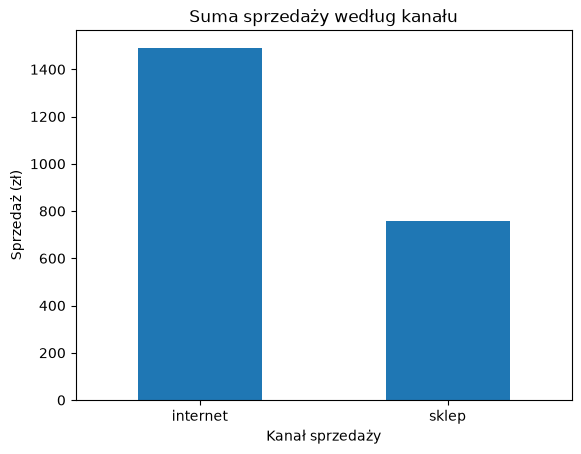

In [9]:
sprzedaz = df.groupby("kanal")[
    "wartosc"
].sum()

sprzedaz.plot(kind="bar")

plt.title("Suma sprzedaży według kanału")
plt.xlabel("Kanał sprzedaży")
plt.ylabel("Sprzedaż (zł)")
plt.xticks(rotation=0)
plt.show()

## Wnioski z analizy

1. Sprzedaż internetowa wyniosła 1490 zł, natomiast sprzedaż w sklepie wyniosła 760 zł.

2. W obu kanałach było po 6 zamówień, ale średnia wartość zamówienia w internecie była wyższa niż w sklepie.